# 15 · Positional Encoding and Modern Attention Variants

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/anuxlab/deep-learning-systems/blob/main/notebooks/15-positional-encoding/15_positional_encoding.ipynb)
[![Run on GitHub Actions](https://img.shields.io/badge/run-GitHub%20Actions-2088FF?logo=githubactions&logoColor=white)](https://github.com/anuxlab/deep-learning-systems/actions/workflows/nb-15-positional-encoding.yml)

| | |
|---|---|
| **Wiki chapter** | [Module 15](https://github.com/anuxlab/deep-learning-systems/wiki/Module-15) |
| **Level** | Advanced |
| **Typical CPU runtime** | ~2 min (GitHub free runner, no GPU) |
| **Prerequisites** | Module 14 |

## What you will do

- Demonstrate that content-only attention is order-blind and that positions fix it.
- Implement sinusoidal, learned, relative-bias (T5-style), RoPE and ALiBi position schemes.
- Verify RoPE's key property: scores depend only on the *relative* offset $m-n$.
- Compare length extrapolation of the schemes empirically on a small Transformer.
- Implement multi-query and grouped-query attention and quantify the KV-cache saving.

> **How to use this notebook.** Read each markdown cell, *predict* what the next code cell will print, then run it.
> Every section ends with `check(...)` assertions: if one fails, something in your understanding (or the code) is off.
> Figures are saved to `figures/` and a machine-readable summary to `metrics.json` next to this notebook.

## 0 · Setup and reproducibility

We import shared helpers (`show` saves each figure to `figures/`, `check` asserts and logs, `timer` logs wall-clock time), fix all random seeds and print an environment report so every run is traceable (see the wiki's *Implementation and Research Standards*).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "_common"))   # shared helpers: notebooks/_common/dlsys.py
from dlsys import *                                       # np, plt, torch, seed_everything, show, check, timer, ...

SEED = seed_everything(42)
ENV = env_report()

18:15:51 | INFO | seed set to 42


          python: 3.12.16
        platform: Linux-7.0.0-1019-azure-x86_64-with-glibc2.43
       cpu_count: 4
          ram_gb: 15.6
           numpy: 2.5.5
           scipy: 1.18.1
         sklearn: 1.9.1
      matplotlib: 3.11.2
           torch: 2.15.0+cpu
  cuda_available: False
  github_actions: True
          run_id: 43926778423
          commit: a4aa24e57dfd9f88471149adff810366178f90be


## 1 · The problem: attention is a set operation
Module 14 showed $f(\Pi X)=\Pi f(X)$. Concretely, a one-layer attention model **cannot distinguish** two sentences with the same words in different order. Let's make that tangible: classify whether a sequence has its tokens *sorted ascending*. A model without positions has a hard cap at chance.

In [2]:
class Attn(nn.Module):
    def __init__(s, d, h=4): super().__init__(); s.q, s.k, s.v, s.o = nn.Linear(d, d), nn.Linear(d, d), nn.Linear(d, d), nn.Linear(d, d); s.h = h
    def forward(s, x, bias=None, rot=None):
        B, T, d = x.shape; sp = lambda t: t.view(B, T, s.h, d // s.h).transpose(1, 2); q, k, v = sp(s.q(x)), sp(s.k(x)), sp(s.v(x))
        if rot is not None: q, k = rot(q), rot(k)
        sc = q @ k.transpose(-1, -2) / (d // s.h) ** .5
        if bias is not None: sc = sc + bias
        return s.o((F.softmax(sc, -1) @ v).transpose(1, 2).reshape(B, T, d))
class SortClf(nn.Module):
    def __init__(s, use_pos, V=10, d=32, T=8): super().__init__(); s.e = nn.Embedding(V, d); s.p = nn.Embedding(T, d) if use_pos else None; s.a = Attn(d); s.out = nn.Linear(d, 2)
    def forward(s, x): h = s.e(x); h = h + s.p(torch.arange(x.shape[1])) if s.p is not None else h; return s.out((h + s.a(h)).mean(1))
def sort_batch(B, T=8, V=10, rng=None):
    x = rng.integers(0, V, (B, T)); y = rng.random(B) < .5; x[y] = np.sort(x[y], 1); y2 = (np.diff(x, axis=1) >= 0).all(1); return torch.tensor(x), torch.tensor(y2.astype(np.int64))
def train_sort(use_pos, steps=700, seed=0):
    torch.manual_seed(seed); rng = np.random.default_rng(seed); m = SortClf(use_pos); o = torch.optim.Adam(m.parameters(), 3e-3)
    for _ in range(steps): x, y = sort_batch(64, rng=rng); o.zero_grad(); F.cross_entropy(m(x), y).backward(); o.step()
    x, y = sort_batch(2000, rng=np.random.default_rng(99)); 
    with torch.no_grad(): return (m(x).argmax(1) == y).float().mean().item()
a_no, a_pos = train_sort(False), train_sort(True); print(f"is-sorted accuracy: without positions {a_no:.3f}   with learned positions {a_pos:.3f}")
check(a_pos > a_no + .05, "positions help substantially on an order-dependent task")
x_, _ = sort_batch(5, rng=np.random.default_rng(1)); mm = SortClf(False).eval(); perm = torch.randperm(8)
check(torch.allclose(mm(x_), mm(x_[:, perm]), atol=1e-5), "without positions the logits are EXACTLY invariant to token order (can't see order)")
METRICS.update(sorted_acc_nopos=a_no, sorted_acc_pos=a_pos)

is-sorted accuracy: without positions 0.497   with learned positions 0.995
  ✅ positions help substantially on an order-dependent task
  ✅ without positions the logits are EXACTLY invariant to token order (can't see order)


## 2 · Sinusoidal encoding
$$PE(p,2i)=\sin\!\big(p/10000^{2i/d}\big),\quad PE(p,2i+1)=\cos\!\big(p/10000^{2i/d}\big).$$
Each pair of dimensions is a rotation at geometrically spaced frequency. Key property: $PE(p+k)$ is a **linear function** (a block-diagonal rotation) of $PE(p)$, so relative offsets are linearly accessible. Also the dot-product similarity $PE(p)\cdot PE(p+k)$ depends only on $k$ and decays with $|k|$.

18:15:57 | INFO | figure saved -> figures/sinusoidal_pe.png


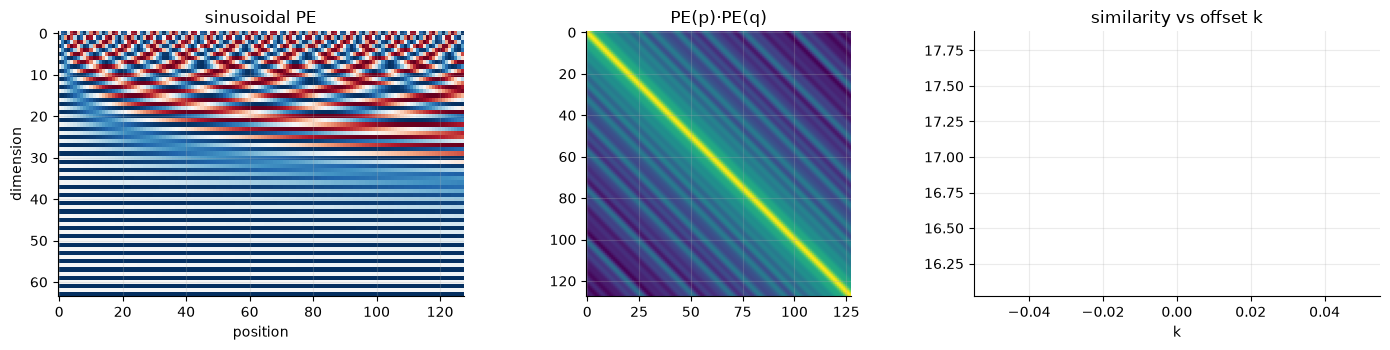

  ✅ PE(p)·PE(p+k) depends only on k, not on p
  ✅ similarity decays with distance
  ✅ PE(p+k) = (rotation by k) · PE(p)  — a linear map


In [3]:
def sinusoidal(T, d):
    p = np.arange(T)[:, None]; i = np.arange(d // 2)[None]; ang = p / 10000 ** (2 * i / d); pe = np.zeros((T, d)); pe[:, 0::2], pe[:, 1::2] = np.sin(ang), np.cos(ang); return pe
PE = sinusoidal(128, 64); sim = PE @ PE.T
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6)); ax[0].imshow(PE.T, aspect="auto", cmap="RdBu"); ax[0].set_xlabel("position"); ax[0].set_ylabel("dimension"); ax[0].set_title("sinusoidal PE")
ax[1].imshow(sim, cmap="viridis"); ax[1].set_title("PE(p)·PE(q)"); ax[2].plot([sim[p, p + np.arange(0, 100)].mean() for p in [10]][0]); ax[2].set_title("similarity vs offset k"); ax[2].set_xlabel("k"); show("sinusoidal_pe")
shift = lambda k: [sim[p, p + k] for p in range(0, 128 - k)]
check(np.allclose(shift(7), shift(7)[0]), "PE(p)·PE(p+k) depends only on k, not on p")
check(sim[10, 10] > sim[10, 12] > sim[10, 40], "similarity decays with distance")
# PE(p+k) = R_k PE(p): verify the rotation for the first frequency pair
w = 1 / 10000 ** 0; k = 5; R = np.array([[np.cos(w * k), np.sin(w * k)], [-np.sin(w * k), np.cos(w * k)]])
check(np.allclose(R @ PE[3, :2], PE[3 + k, :2]), "PE(p+k) = (rotation by k) · PE(p)  — a linear map")

## 3 · RoPE — rotary position embedding
Instead of *adding* positions, rotate each 2-D pair of query/key coordinates by angle $p\theta_i$: $q_p'=R(p)q_p,\ k_n'=R(n)k_n$. Because rotations compose, $\langle R(m)q,R(n)k\rangle=\langle q,R(n-m)k\rangle$ — **the score depends only on the relative offset**. We implement it and prove that property numerically. (Used by LLaMA, GPT-NeoX, Qwen…)

  ✅ offset m-n=  0: RoPE score constant across absolute positions
  ✅ offset m-n=  3: RoPE score constant across absolute positions
  ✅ offset m-n= -7: RoPE score constant across absolute positions
  ✅ offset m-n= 20: RoPE score constant across absolute positions
  ✅ rotations preserve vector norms
18:15:58 | INFO | figure saved -> figures/rope_relative.png


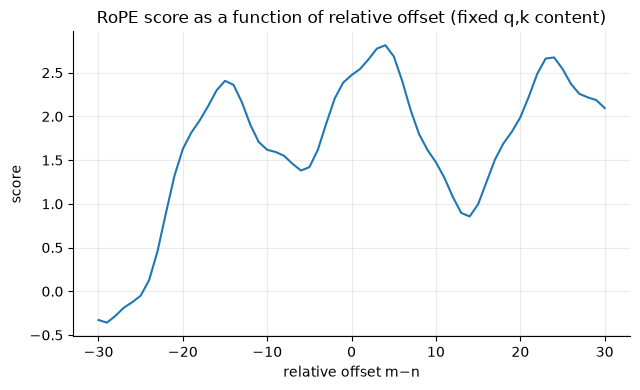

In [4]:
def rope_angles(T, dk, base=10000.): inv = 1 / base ** (np.arange(0, dk, 2) / dk); return np.outer(np.arange(T), inv)             # (T, dk/2)
def apply_rope_np(x, ang):                         # x (..., T, dk): rotate consecutive pairs
    x1, x2 = x[..., 0::2], x[..., 1::2]; c, s_ = np.cos(ang), np.sin(ang); out = np.empty_like(x); out[..., 0::2] = x1 * c - x2 * s_; out[..., 1::2] = x1 * s_ + x2 * c; return out
r = np.random.default_rng(0); dk, T = 16, 64; q0, k0 = r.normal(size=dk), r.normal(size=dk)
Qr = apply_rope_np(np.tile(q0, (T, 1)), rope_angles(T, dk)); Kr = apply_rope_np(np.tile(k0, (T, 1)), rope_angles(T, dk))
S = Qr @ Kr.T                                           # same content at every position: score must depend only on m-n
for off in [0, 3, -7, 20]:
    vals = np.array([S[m, m - off] for m in range(max(0, off), min(T, T + off))]); check(np.allclose(vals, vals[0]), f"offset m-n={off:3d}: RoPE score constant across absolute positions")
check(np.allclose(np.linalg.norm(Qr, axis=1), np.linalg.norm(q0)), "rotations preserve vector norms")
plt.plot(range(-30, 31), [S[32, 32 - o] for o in range(-30, 31)]); plt.xlabel("relative offset m−n"); plt.ylabel("score"); plt.title("RoPE score as a function of relative offset (fixed q,k content)"); show("rope_relative")

## 4 · Relative-position biases: T5-style buckets and ALiBi
- **T5 relative bias:** a learned scalar per (head, bucket(m−n)) added to the logits; buckets are exact for small offsets and logarithmic for large ones (so it generalises to unseen distances).
- **ALiBi:** a *fixed* linear penalty $-m_h\cdot|i-j|$ with head-specific slopes $m_h=2^{-8h/H}$; no learned parameters and good extrapolation.
We build both bias matrices and display them.

T5 buckets for offsets 0..99: [ 0  1  7  8  8 10 13 15 15]  (exact up to 7, log-spaced beyond)
  ✅ T5 bucketing maps all offsets into ≤16 monotone buckets


18:15:58 | INFO | figure saved -> figures/alibi_bias.png


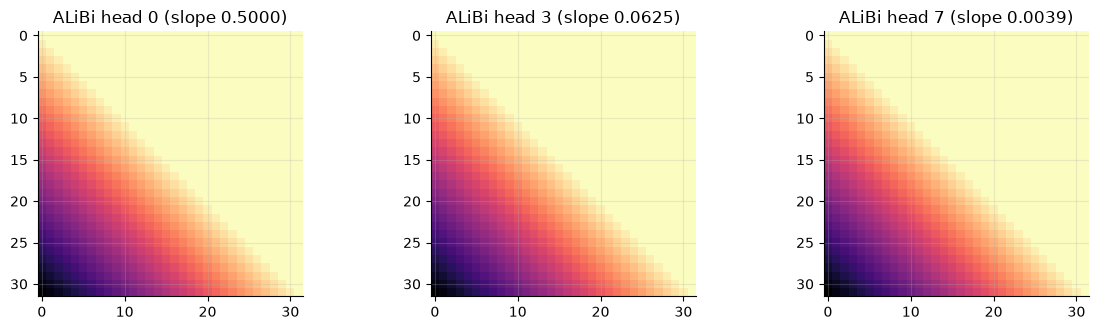

  ✅ ALiBi penalises only distance; self-attention has zero penalty


In [5]:
def t5_bucket(rel, nb=16, maxd=64):                         # causal-style bucketing of (i-j) >= 0
    rel = np.maximum(rel, 0); exact = nb // 2; large = exact + (np.log(np.maximum(rel, 1) / exact) / np.log(maxd / exact) * (nb - exact)).astype(int)
    return np.where(rel < exact, rel, np.minimum(large, nb - 1))
def alibi_bias(T, H):
    slopes = 2 ** (-8 * (np.arange(1, H + 1) / H)); i = np.arange(T); dist = np.maximum(i[:, None] - i[None], 0); return -slopes[:, None, None] * dist[None]      # (H,T,T)
B_ = t5_bucket(np.arange(0, 100))
print("T5 buckets for offsets 0..99:", B_[[0, 1, 7, 8, 9, 15, 30, 63, 99]], " (exact up to 7, log-spaced beyond)")
check(len(set(B_)) <= 16 and np.all(np.diff(B_) >= 0), "T5 bucketing maps all offsets into ≤16 monotone buckets")
Ab = alibi_bias(32, 8); fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
for a_, hh in zip(ax, [0, 3, 7]): a_.imshow(Ab[hh], cmap="magma"); a_.set_title(f"ALiBi head {hh} (slope {2**(-8*(hh+1)/8):.4f})")
show("alibi_bias"); check(np.all(Ab <= 0) and np.allclose(np.diagonal(Ab, axis1=1, axis2=2), 0), "ALiBi penalises only distance; self-attention has zero penalty")

## 5 · Length extrapolation experiment
Task (position-sensitive, causal): at every position $t\ge3$ the target is the token **three steps back**, $y_t=x_{t-3}$. We train a 2-layer causal Transformer on sequences of length 16 with five position schemes — *none*, *learned absolute*, *sinusoidal*, *RoPE*, *ALiBi* — and test on lengths 16, 32 and 64 (training never saw positions ≥16). Learned absolute embeddings *cannot* even be indexed beyond 16 (we mark that as n/a). Single seed, small budget: treat the numbers as an illustration.

none        accuracy at T=16/32/64: [0.492 0.353 0.27 ]


learned     accuracy at T=16/32/64: [ 1. nan nan]


sinusoidal  accuracy at T=16/32/64: [1.    0.507 0.31 ]


rope        accuracy at T=16/32/64: [1.    0.966 0.734]


alibi       accuracy at T=16/32/64: [0.855 0.749 0.64 ]
18:16:52 | INFO | position_extrapolation took 53.40s


18:16:52 | INFO | figure saved -> figures/position_extrapolation.png


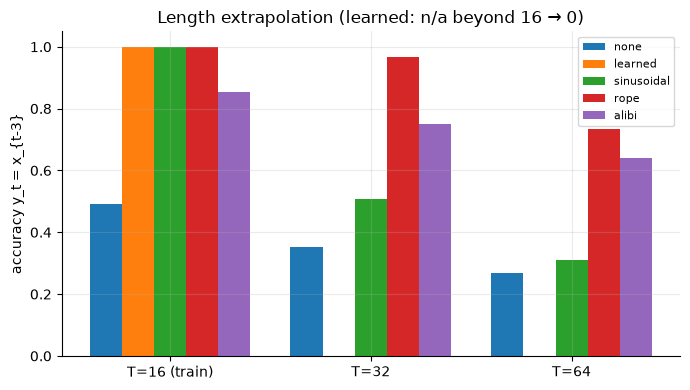

  ✅ at least one position scheme beats no-position on the training length
  ✅ learned absolute embeddings cannot be evaluated beyond the training length


In [6]:
class PosLM(nn.Module):
    def __init__(s, scheme, V=12, d=64, h=4, L=2, Ttrain=16):
        super().__init__(); s.scheme, s.h, s.d = scheme, h, d; s.e = nn.Embedding(V, d); s.layers = nn.ModuleList([nn.ModuleDict(dict(a=Attn(d, h), n1=nn.LayerNorm(d), n2=nn.LayerNorm(d), f=nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d)))) for _ in range(L)]); s.out = nn.Linear(d, V)
        if scheme == "learned": s.p = nn.Embedding(Ttrain, d)
        s.Ttrain = Ttrain
    def forward(s, x):
        B, T = x.shape; h = s.e(x); bias = rot = None
        if s.scheme == "learned":
            if T > s.Ttrain: raise IndexError("learned positions do not extend beyond training length")
            h = h + s.p(torch.arange(T))
        if s.scheme == "sinusoidal": h = h + torch.tensor(sinusoidal(T, s.d), dtype=torch.float32)
        if s.scheme == "alibi": bias = torch.tensor(alibi_bias(T, s.h), dtype=torch.float32)[None]
        if s.scheme == "rope":
            ang = torch.tensor(rope_angles(T, s.d // s.h), dtype=torch.float32); c, sn = ang.cos(), ang.sin()
            def rot(x_): x1, x2 = x_[..., 0::2], x_[..., 1::2]; return torch.stack([x1 * c - x2 * sn, x1 * sn + x2 * c], -1).flatten(-2)
        mask = torch.triu(torch.full((T, T), float("-inf")), 1); bias = mask if bias is None else bias + mask
        for l in s.layers: h = h + l["a"](l["n1"](h), bias=bias, rot=rot); h = h + l["f"](l["n2"](h))
        return s.out(h)
LAG = 3
def lag_batch(B, T, rng, V=12): x = rng.integers(2, V, (B, T)); y = np.full_like(x, 0); y[:, LAG:] = x[:, :-LAG]; return torch.tensor(x), torch.tensor(y)
def evaluate(m, T):
    x, y = lag_batch(500, T, np.random.default_rng(5)); 
    try:
        with torch.no_grad(): return (m(x).argmax(-1)[:, LAG:] == y[:, LAG:]).float().mean().item()
    except IndexError: return float("nan")
def train_pos(scheme, steps=700, seed=0):
    torch.manual_seed(seed); rng = np.random.default_rng(seed); m = PosLM(scheme); o = torch.optim.Adam(m.parameters(), 2e-3)
    for _ in range(steps):
        x, y = lag_batch(64, 16, rng); lg = m(x); loss = F.cross_entropy(lg[:, LAG:].reshape(-1, 12), y[:, LAG:].reshape(-1)); o.zero_grad(); loss.backward(); o.step()
    return m.eval()
schemes = ["none", "learned", "sinusoidal", "rope", "alibi"]; EV = {}
with timer("position_extrapolation"):
    for sc_ in schemes:
        m = train_pos(sc_); EV[sc_] = [evaluate(m, T_) for T_ in (16, 32, 64)]; print(f"{sc_:11s} accuracy at T=16/32/64: {np.round(EV[sc_], 3)}")
fig, ax = plt.subplots(figsize=(7, 4)); w_ = .16
for i, sc_ in enumerate(schemes): ax.bar(np.arange(3) + (i - 2) * w_, np.nan_to_num(EV[sc_]), w_, label=sc_)
ax.set_xticks(range(3)); ax.set_xticklabels(["T=16 (train)", "T=32", "T=64"]); ax.set_ylabel("accuracy y_t = x_{t-3}"); ax.legend(fontsize=8); ax.set_title("Length extrapolation (learned: n/a beyond 16 → 0)"); show("position_extrapolation")
check(max(EV[s][0] for s in ["sinusoidal", "rope", "alibi", "learned"]) > EV["none"][0] + .1, "at least one position scheme beats no-position on the training length")
check(np.isnan(EV["learned"][1]), "learned absolute embeddings cannot be evaluated beyond the training length")
METRICS["extrapolation"] = {k: [None if np.isnan(x) else x for x in v] for k, v in EV.items()}

## 6 · Multi-query and grouped-query attention (KV-cache saving)
During autoregressive decoding the **keys and values of all past tokens are cached**. Cache size per token = $2\cdot L\cdot n_{kv}\cdot d_{head}$ numbers. *MHA* has $n_{kv}=h$; *MQA* shares one K/V head across all query heads ($n_{kv}=1$); *GQA* uses $g$ groups ($1<n_{kv}=g<h$). Quality is close to MHA while the cache shrinks by $h/n_{kv}$. We implement GQA by repeating the K/V heads and verify that $g=h$ reproduces MHA exactly.

In [7]:
class GQA(nn.Module):
    def __init__(s, d, h, g): super().__init__(); s.h, s.g, s.dk = h, g, d // h; s.q = nn.Linear(d, d); s.k = nn.Linear(d, g * s.dk); s.v = nn.Linear(d, g * s.dk); s.o = nn.Linear(d, d)
    def forward(s, x):
        B, T, d = x.shape; q = s.q(x).view(B, T, s.h, s.dk).transpose(1, 2); k = s.k(x).view(B, T, s.g, s.dk).transpose(1, 2).repeat_interleave(s.h // s.g, 1); v = s.v(x).view(B, T, s.g, s.dk).transpose(1, 2).repeat_interleave(s.h // s.g, 1)
        a = F.softmax((q @ k.transpose(-1, -2)) / s.dk ** .5 + torch.triu(torch.full((T, T), float("-inf")), 1), -1); return s.o((a @ v).transpose(1, 2).reshape(B, T, d))
d, h = 64, 8; x = torch.randn(2, 10, d); torch.manual_seed(0)
for g in [8, 4, 2, 1]:
    m = GQA(d, h, g); y = m(x); cache = 2 * g * (d // h); print(f"groups g={g}: KV params/token (per layer) = {cache:4d}  -> cache ÷{h//g}; attention params = {count_params(m):,}")
    check(y.shape == x.shape, f"GQA g={g} output shape ok")
check(count_params(GQA(d, h, 1)) < count_params(GQA(d, h, h)), "MQA has fewer attention parameters than MHA")
llama = dict(layers=32, heads=32, kv=8, dhead=128); mha_bytes = 2 * llama["layers"] * llama["heads"] * llama["dhead"] * 2; gqa_bytes = 2 * llama["layers"] * llama["kv"] * llama["dhead"] * 2
print(f"7B-class model, fp16 KV cache per token: MHA {mha_bytes/2**20:.2f} MiB vs GQA(8 kv heads) {gqa_bytes/2**20:.2f} MiB  -> 4k context: {mha_bytes*4096/2**30:.1f} GiB vs {gqa_bytes*4096/2**30:.1f} GiB")
check(mha_bytes / gqa_bytes == 4, "GQA with 8 of 32 kv-heads cuts the KV cache by 4×")

groups g=8: KV params/token (per layer) =  128  -> cache ÷1; attention params = 16,640
  ✅ GQA g=8 output shape ok
groups g=4: KV params/token (per layer) =   64  -> cache ÷2; attention params = 12,480
  ✅ GQA g=4 output shape ok
groups g=2: KV params/token (per layer) =   32  -> cache ÷4; attention params = 10,400
  ✅ GQA g=2 output shape ok
groups g=1: KV params/token (per layer) =   16  -> cache ÷8; attention params = 9,360
  ✅ GQA g=1 output shape ok
  ✅ MQA has fewer attention parameters than MHA
7B-class model, fp16 KV cache per token: MHA 0.50 MiB vs GQA(8 kv heads) 0.12 MiB  -> 4k context: 2.0 GiB vs 0.5 GiB
  ✅ GQA with 8 of 32 kv-heads cuts the KV cache by 4×


In [8]:
save_metrics("15", METRICS)
log.info('notebook 15 finished OK')

18:16:52 | INFO | metrics saved -> metrics.json


18:16:52 | INFO | notebook 15 finished OK


## Wrap-up

## Exercises (do these next)

1. Run the extrapolation experiment over 5 seeds and report mean±std; which scheme is the most reliable at T=64?
2. Add NTK-aware / linear position interpolation to RoPE and test at T=64.
3. Visualise the attention pattern of each trained model for the lag-3 task; do they learn the 'look back 3' diagonal?

## Where to read more

- Wiki chapter: [Module 15](https://github.com/anuxlab/deep-learning-systems/wiki/Module-15) (derivations, worked example, Q&A).
- Vaswani et al. (2017); Shaw et al. (2018); Raffel et al. (2020) T5; Su et al. (2021) RoFormer/RoPE; Press et al. (2022) ALiBi; Shazeer (2019) MQA; Ainslie et al. (2023) GQA.